## **Data Understanding**

**Dataset sources and purpose**
The dataset used for this study contains tweets labeled for hateful or non-hateful content and is suitable for developing and evaluating deep learning models for hate-speech detection, including RNN, LSTM, Deep CNN, and BERT-based architectures. The training set consists of 31,962 examples and the test set consists of 17,197 examples. Each row contains an `id`, a `tweet` (text), and a `label` (target).

**Variables**

* `id` — Unique identifier for each sample.
* `tweet` — Raw text of the tweet (string). This is the feature used for model input.
* `label` — Target label indicating class membership (hateful vs non-hateful). The dataset uses a categorical encoding; exact label values and their meaning are available in the dataset table.

**Missing values and integrity checks**
All of the `id`, `tweet`, and `label` fields were present for the entire training and test datasets — no missing values were found in these columns. This facilitates straightforward model training without additional imputation for missing targets or text.

**Text characteristics**

* The tweets are short-form text as expected for social media data, with variable length. Summary statistics for text length (characters and word counts) were computed; most tweets fall well under standard sequence length thresholds used by deep learning models, though some outliers exist.
* Tokenization uncovered common tokens such as `user` (the dataset contains anonymized mentions like `@user`) and frequent English stopwords. There are also text-encoding artifacts such as `ð` and `â` appearing in the token list, suggesting possible UTF-8 or dataset export artifacts that should be cleaned during preprocessing.

**Class distribution and balance**

* The label distribution was computed and included in the EDA output. If the classes are imbalanced (e.g., far fewer hateful examples), this needs to be addressed during model training using techniques such as class weighting, resampling (oversampling minority class or undersampling majority), or focal loss for neural networks.

**Frequent words and n-grams**

* Top unigrams and bigrams were extracted to provide insight into recurring words and phrases. High-frequency tokens include anonymized mentions and common stopwords; frequent n-grams can help with designing tokenization and feature extraction strategies (e.g., whether to use subword tokenizers for BERT or include bigram features for CNN/RNN inputs).

**Data quality notes & suggested cleaning steps**

1. **Remove or normalize anonymized mentions (`@user`)** — either remove them or replace with a consistent token `<USER>` since they carry limited semantic content but are extremely frequent.
2. **Fix encoding artifacts** — tokens like `ð` and `â` likely come from encoding issues. Normalize text to UTF-8 and remove or replace such artifacts.
3. **Lowercasing, punctuation handling, and URL/hashtag handling** — decide whether to remove URLs, lower-case all text, split or keep hashtags, etc. For BERT-based models, minimal cleaning is often best (let BERT's tokenizer handle raw text); for RNN/CNN you may want more explicit normalization.
4. **Stopword removal** — optional for classical ML and some CNN/RNN pipelines, but not recommended for transformer models.
5. **Tokenization** — use a tokenizer appropriate for each model: word/subword tokenizers for RNN/CNN; BERT’s WordPiece/BPE tokenizer for transformer models.

**Implications for modeling (RNN, LSTM, Deep CNN, BERT)**

* **Sequence length**: The distribution of tweet lengths suggests using a maximum sequence length between **128–256** tokens for RNN/LSTM/CNN pipelines should cover the vast majority of examples while keeping compute manageable. For BERT, you may use up to **512** tokens if desired, but 128–256 usually suffice for tweets. Set `max_len` after inspecting the 90th/95th percentile of word/token lengths (the notebook shows descriptive stats to help choose).
* **Vocabulary & tokenization**: For RNN/LSTM/CNN, build a vocabulary after cleaning and consider using pretrained embeddings (GloVe/Twitter embeddings) if available. For BERT, fine-tune a pretrained BERT tokenizer and model — minimal text normalization is preferable.
* **Class imbalance**: If the dataset is imbalanced, use class weighting in the loss function, oversampling minority class in mini-batches, or advanced methods like focal loss. These are especially important for deep CNN/RNN/LSTM where the model might otherwise learn the majority class.
* **Evaluation**: Use precision, recall, and F1 (especially per-class F1) rather than accuracy alone due to possible class imbalance. Report confusion matrices and, if applicable, ROC-AUC for binary detection.

**Summary**
The dataset is well-structured and ready for model development after standard text cleaning. The EDA highlights tokenization considerations and potential encoding artifacts to fix. For experimental work, include robust preprocessing pipelines tuned separately for classical sequence models (RNN/LSTM/CNN) and transformer-based models (BERT).

## **Data Preparation**

### Download Data

In [ ]:
!pip install evaluate transformers torch vaderSentiment emoji contractions -qq

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("arkhoshghalb/twitter-sentiment-analysis-hatred-speech")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'twitter-sentiment-analysis-hatred-speech' dataset.
Path to dataset files: /kaggle/input/twitter-sentiment-analysis-hatred-speech


In [ ]:
import re
import nltk
import emoji
import torch
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from contractions import fix
from evaluate import load
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag, word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from torch.utils.data import Dataset
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, LSTM, Conv1D, GlobalMaxPooling1D, Dropout, BatchNormalization
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from transformers.trainer_callback import EarlyStoppingCallback
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import warnings
warnings.filterwarnings('ignore')

# Download NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('stopwords')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
df_train = pd.read_csv(path + '/train.csv')
df_test = pd.read_csv(path + '/test.csv')

### Data Cleaning

In [ ]:
lemmatizer = WordNetLemmatizer()
analyzer = SentimentIntensityAnalyzer()
stop_words = set(stopwords.words('english')) - {'no', 'nor', 'not'}

In [ ]:
# Convert POS tag to wordnet tag
def get_wordnet_pos(word):
    tag = pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

# Normalize slang
def normalize_slang(text):
    slang_dict = {
        "u": "you", "r": "are", "ur": "your", "luv": "love",
        "pls": "please", "thx": "thanks", "omg": "oh my god",
        "idk": "i do not know", "btw": "by the way",
        "imho": "in my humble opinion", "lmao": "laughing my ass off",
        "lol": "laugh out loud", "wtf": "what the fuck"
    }
    for k, v in slang_dict.items():
        text = re.sub(r'\b' + k + r'\b', v, text)
    return text

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = fix(text)  # expand contractions
    text = emoji.demojize(text)  # convert emojis to text
    text = re.sub(r'@[\w_]+', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'#', ' ', text)
    text = re.sub(r'[^a-z\s:]', ' ', text)
    text = re.sub(r':\s*', ' ', text)
    text = normalize_slang(text)
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenize, remove stopwords, lemmatize
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in stop_words]
    lemmas = [lemmatizer.lemmatize(t, get_wordnet_pos(t)) for t in tokens]
    return " ".join(lemmas)

df_train['clean_tweet'] = df_train['tweet'].apply(clean_text)
df_test['clean_tweet'] = df_test['tweet'].apply(clean_text)

### Data Labelling

In [ ]:
def get_sentiment_label(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

df_train['sentiment'] = df_train['clean_tweet'].apply(get_sentiment_label)

In [ ]:
df_train.drop('label', axis=1, inplace=True)

In [ ]:
df_train

,id,tweet,clean_tweet,sentiment
0,1,@user when a father is dysfunctional and is s...,father dysfunctional selfish drag kid dysfunct...,negative
1,2,@user @user thanks for #lyft credit i can't us...,thanks lyft credit not use not offer wheelchai...,positive
2,3,bihday your majesty,bihday majesty,neutral
3,4,#model i love u take with u all the time in ...,model love take time,positive
4,5,factsguide: society now #motivation,factsguide society motivation,positive
...,...,...,...,...
31957,31958,ate @user isz that youuu?ðððððð...,ate isz youuu,neutral
31958,31959,to see nina turner on the airwaves trying to...,see nina turner airwave try wrap mantle genuin...,positive
31959,31960,listening to sad songs on a monday morning otw...,listen sad song monday morning otw work sad,negative
31960,31961,"@user #sikh #temple vandalised in in #calgary,...",sikh temple vandalise calgary wso condemns act,negative


### Data Preprocessing

#### Encode labels

In [ ]:
le = LabelEncoder()
df_train['label_encoded'] = le.fit_transform(df_train['sentiment'])

#### Data Splitting

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    df_train['clean_tweet'],
    df_train['label_encoded'],
    test_size=0.2,
    random_state=8102025
)

#### Tokenization

In [ ]:
max_words = 15000
max_len = 128

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=max_len)
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(X_val), maxlen=max_len)

#### One-hot encode labels

In [ ]:
y_train_cat = to_categorical(y_train)
y_val_cat = to_categorical(y_val)

#### Compute class weights

In [ ]:
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

Class Weights: {0: np.float64(1.594872754491018), 1: np.float64(1.2738006277088627), 2: np.float64(0.6297473030885178)}


### Data Preprocessing for BERT

#### Tokenizer dan Encoding Data

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
MAX_LEN = 128

def encode_texts(texts):
    return tokenizer(
        texts.tolist(),
        truncation=True,
        padding='max_length',
        max_length=MAX_LEN,
        return_tensors='pt'
    )

X_train_enc = encode_texts(X_train)
X_val_enc = encode_texts(X_val)

#### Dataset Class

In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

train_dataset = SentimentDataset(X_train_enc, y_train.to_numpy())
val_dataset = SentimentDataset(X_val_enc, y_val.to_numpy())

#### Class Weights

In [ ]:
class_weights_bert = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_bert = torch.tensor(class_weights_bert, dtype=torch.float).to(device)
print("Class Weights:", class_weights_bert)

Class Weights: tensor([1.5949, 1.2738, 0.6297], device='cuda:0')


## **Modelling And Evaluation**

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1618, patience=1, verbose=1),
]

# Function to evaluate each model
def evaluate_model(model, X_val, y_val_true, model_name):
    preds = np.argmax(model.predict(X_val), axis=1)
    print(f"=== {model_name} ===")
    print("Accuracy:", accuracy_score(np.argmax(y_val_true, axis=1), preds))
    print(classification_report(np.argmax(y_val_true, axis=1), preds, target_names=le.classes_))
    print()

def plot_training_history(history, model_name):
    """
    Plot accuracy and loss for Keras or HuggingFace Trainer (BERT).
    - history: Keras History object or HuggingFace Trainer.state.log_history (list)
    - model_name: str, model name (e.g. 'RNN', 'LSTM', 'CNN', 'BERT')
    """

    plt.figure(figsize=(14,5))

    # --- Case 1: Keras History ---
    if hasattr(history, 'history'):
        hist = history.history
        # Accuracy plot
        plt.subplot(1,2,1)
        plt.plot(hist['accuracy'], label='Train Acc')
        plt.plot(hist['val_accuracy'], label='Val Acc')
        plt.title(f'{model_name} - Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)

        # Loss plot
        plt.subplot(1,2,2)
        plt.plot(hist['loss'], label='Train Loss')
        plt.plot(hist['val_loss'], label='Val Loss')
        plt.title(f'{model_name} - Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)

    # --- Case 2: BERT Trainer ---
    else:
        logs = pd.DataFrame(history)
        if 'loss' in logs.columns:
            logs['loss'] = logs['loss'].rolling(3).mean()
        if 'eval_loss' in logs.columns:
            logs['eval_loss'] = logs['eval_loss'].rolling(3).mean()
        if 'eval_accuracy' in logs.columns:
            logs['eval_accuracy'] = logs['eval_accuracy'].rolling(3).mean()

        # Accuracy plot
        plt.subplot(1,2,1)
        if 'eval_accuracy' in logs.columns:
            plt.plot(logs['step'], logs['eval_accuracy'], label='Val Acc')
        plt.title(f'{model_name} - Accuracy')
        plt.xlabel('Step')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)

        # Loss plot
        plt.subplot(1,2,2)
        if 'loss' in logs.columns:
            plt.plot(logs['step'], logs['loss'], label='Train Loss')
        if 'eval_loss' in logs.columns:
            plt.plot(logs['step'], logs['eval_loss'], label='Val Loss')
        plt.title(f'{model_name} - Loss')
        plt.xlabel('Step')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

### RNN

In [ ]:
rnn_model = Sequential([
    Embedding(max_words, 128, input_length=max_len),
    SimpleRNN(128, return_sequences=False, dropout=0.3, recurrent_dropout=0.3),
    BatchNormalization(),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(3, activation='softmax')
])

rnn_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history_rnn = rnn_model.fit(
    X_train_seq, y_train_cat,
    validation_data=(X_val_seq, y_val_cat),
    epochs=5,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.3364 - loss: 1.3280 - val_accuracy: 0.5503 - val_loss: 1.0605 - learning_rate: 0.0010
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.3754 - loss: 1.1053 - val_accuracy: 0.4286 - val_loss: 1.0414 - learning_rate: 0.0010
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.4487 - loss: 1.0393 - val_accuracy: 0.5822 - val_loss: 0.8865 - learning_rate: 0.0010
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.5981 - loss: 0.8689 - val_accuracy: 0.7042 - val_loss: 0.6948 - learning_rate: 0.0010
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.7711 - loss: 0.6003 - val_accuracy: 0.7785 - val_loss: 0.5826 - learning_rate: 0.0010
Epoch 6/10
399/400 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8441 - loss: 0.4196
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00016180000768508762.
400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8441 - loss: 

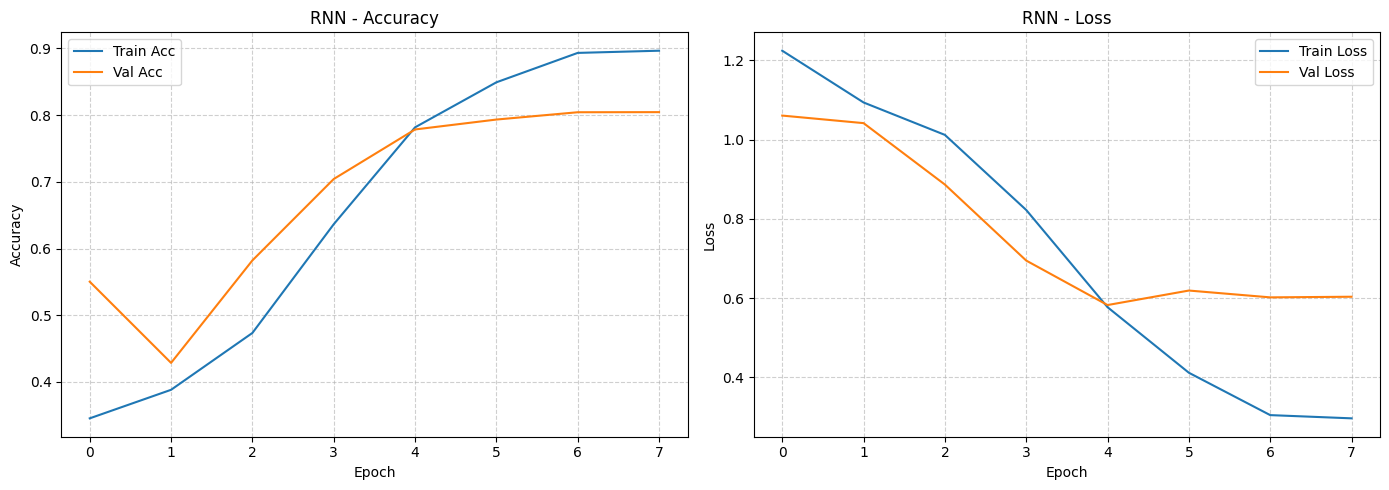

In [ ]:
plot_training_history(history_rnn, "RNN")

In [ ]:
evaluate_model(rnn_model, X_val_seq, y_val_cat, "RNN")

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
=== RNN ===
Accuracy: 0.7785077428437354
              precision    recall  f1-score   support

    negative       0.60      0.62      0.61      1355
     neutral       0.70      0.84      0.76      1619
    positive       0.91      0.81      0.86      3419

    accuracy                           0.78      6393
   macro avg       0.74      0.76      0.74      6393
weighted avg       0.79      0.78      0.78      6393




### LSTM

In [ ]:
lstm_model = Sequential([
    Embedding(max_words, 128, input_length=max_len),
    LSTM(128, dropout=0.4, recurrent_dropout=0.4, return_sequences=False),
    BatchNormalization(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

lstm_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history_lstm = lstm_model.fit(
    X_train_seq, y_train_cat,
    validation_data=(X_val_seq, y_val_cat),
    epochs=5,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 174s 411ms/step - accuracy: 0.5650 - loss: 0.8862 - val_accuracy: 0.7655 - val_loss: 0.6689 - learning_rate: 0.0010
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 167s 417ms/step - accuracy: 0.8743 - loss: 0.3591 - val_accuracy: 0.8775 - val_loss: 0.3455 - learning_rate: 0.0010
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 164s 410ms/step - accuracy: 0.9185 - loss: 0.2261 - val_accuracy: 0.9004 - val_loss: 0.2905 - learning_rate: 0.0010
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.9426 - loss: 0.1605
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00016180000768508762.
400/400 ━━━━━━━━━━━━━━━━━━━━ 168s 421ms/step - accuracy: 0.9426 - loss: 0.1605 - val_accuracy: 0.8990 - val_loss: 0.3099 - learning_rate: 0.0010
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - accuracy: 0.9581 - loss: 0.1220
Epoch 5: ReduceLROnPlateau reducing learning rate to 2.6179241563659163e-05.
400/400 ━━━━━━━━━━━━━━━━━━━━ 165s 413ms/step - accuracy: 

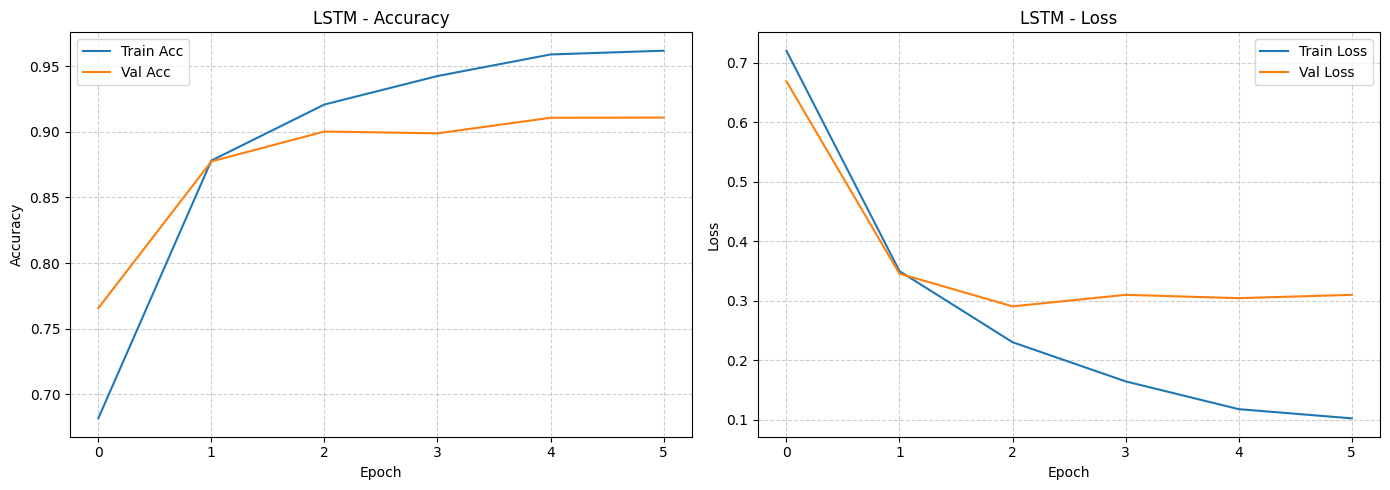

In [ ]:
plot_training_history(history_lstm, "LSTM")

In [ ]:
evaluate_model(lstm_model, X_val_seq, y_val_cat, "LSTM")

200/200 ━━━━━━━━━━━━━━━━━━━━ 16s 77ms/step
=== LSTM ===
Accuracy: 0.9003597684967933
              precision    recall  f1-score   support

    negative       0.77      0.89      0.82      1355
     neutral       0.91      0.92      0.91      1619
    positive       0.96      0.90      0.93      3419

    accuracy                           0.90      6393
   macro avg       0.88      0.90      0.89      6393
weighted avg       0.91      0.90      0.90      6393




### Deep CNN

In [ ]:
cnn_model = Sequential([
    Embedding(max_words, 128, input_length=max_len),
    Conv1D(128, 5, activation='relu'),
    BatchNormalization(),
    Conv1D(64, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(3, activation='softmax')
])

cnn_model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history_cnn = cnn_model.fit(
    X_train_seq, y_train_cat,
    validation_data=(X_val_seq, y_val_cat),
    epochs=5,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.6124 - loss: 0.8254 - val_accuracy: 0.8487 - val_loss: 0.5628 - learning_rate: 0.0010
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9405 - loss: 0.1907 - val_accuracy: 0.9199 - val_loss: 0.2357 - learning_rate: 0.0010
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9724 - loss: 0.0911
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00016180000768508762.
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9724 - loss: 0.0911 - val_accuracy: 0.9285 - val_loss: 0.2488 - learning_rate: 0.0010
Epoch 4/10
390/400 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9839 - loss: 0.0545
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.6179241563659163e-05.
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9839 - loss: 0.0544 - val_accuracy: 0.9354 - val_loss: 0.2543 - learning_rate: 1.6180e-04
Epoch 5/10
399/400 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9919 - loss: 0.0

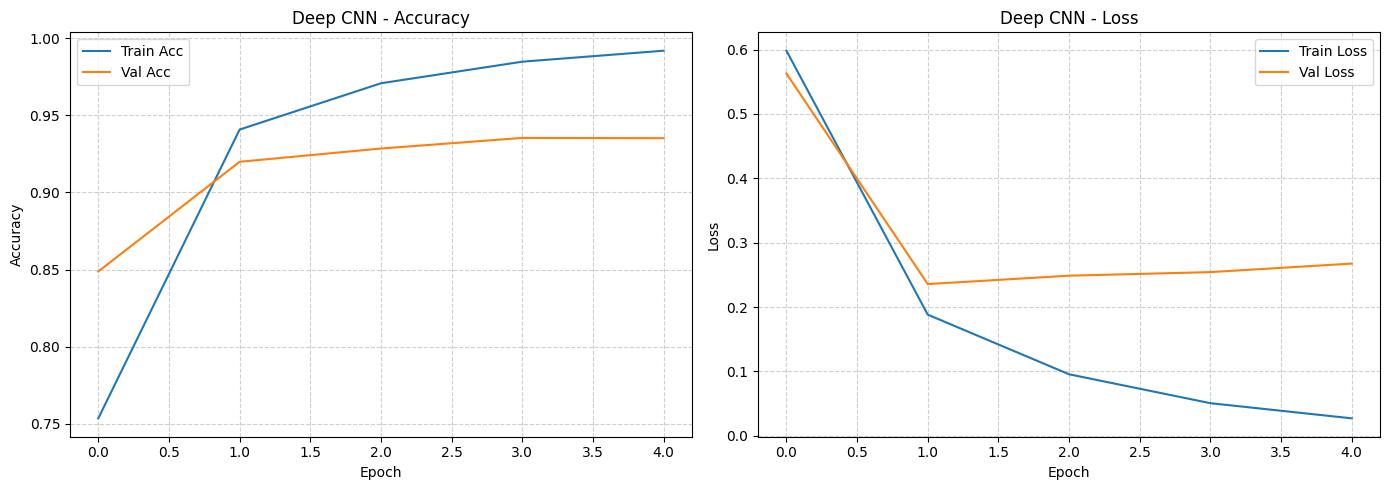

In [ ]:
plot_training_history(history_cnn, "Deep CNN")

In [ ]:
evaluate_model(cnn_model, X_val_seq, y_val_cat, "Deep CNN")

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
=== Deep CNN ===
Accuracy: 0.9199124041920851
              precision    recall  f1-score   support

    negative       0.81      0.93      0.86      1355
     neutral       0.94      0.90      0.92      1619
    positive       0.97      0.93      0.95      3419

    accuracy                           0.92      6393
   macro avg       0.90      0.92      0.91      6393
weighted avg       0.92      0.92      0.92      6393




### BERT

In [ ]:
bert_model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=3)
bert_model.to(device)

# Custom loss function with class weights
def compute_loss(model, inputs, return_outputs=False):
    labels = inputs.pop("labels")
    outputs = model(**inputs)
    logits = outputs.logits
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights_bert)
    loss = loss_fn(logits, labels)
    return (loss, outputs) if return_outputs else loss

metric = load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = metric.compute(predictions=preds, references=labels)
    return acc

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
training_args = TrainingArguments(
    output_dir="./bert-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_strategy="epoch",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    save_total_limit=2,
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.363700,0.246237,0.934147
2,0.165200,0.193079,0.945878
3,0.087900,0.188441,0.952292


TrainOutput(global_step=4797, training_loss=0.20561883388421473, metrics={'train_runtime': 1761.6053, 'train_samples_per_second': 43.544, 'train_steps_per_second': 2.723, 'total_flos': 5045660233415424.0, 'train_loss': 0.20561883388421473, 'epoch': 3.0})

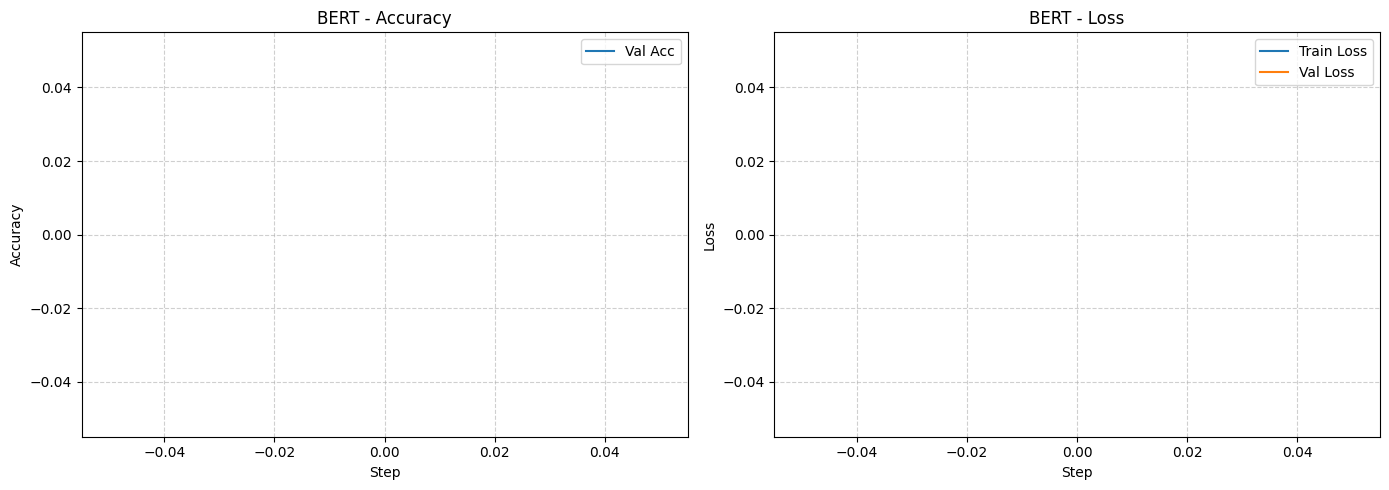

In [ ]:
plot_training_history(trainer.state.log_history, "BERT")

In [ ]:
# Pastikan model ke mode evaluasi
model.eval()

# Kirim data ke device (GPU atau CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Ubah X_val_enc ke tensor dan ke device
input_ids = torch.tensor(X_val_enc['input_ids']).to(device)
attention_mask = torch.tensor(X_val_enc['attention_mask']).to(device)

# Nonaktifkan gradient saat inference
with torch.no_grad():
    outputs = model(input_ids=input_ids, attention_mask=attention_mask)
    logits = outputs.logits
    preds = torch.argmax(logits, dim=1).cpu().numpy()

# Evaluasi
print("=== BERT ===")
print("Accuracy:", accuracy_score(y_val, preds))
print(classification_report(y_val, preds, target_names=le.classes_))

OutOfMemoryError: CUDA out of memory. Tried to allocate 2.34 GiB. GPU 0 has a total capacity of 14.74 GiB of which 1.46 GiB is free. Process 102531 has 13.28 GiB memory in use. Of the allocated memory 11.01 GiB is allocated by PyTorch, and 2.14 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)